# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import KaggleSemanticSegmentationDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 72


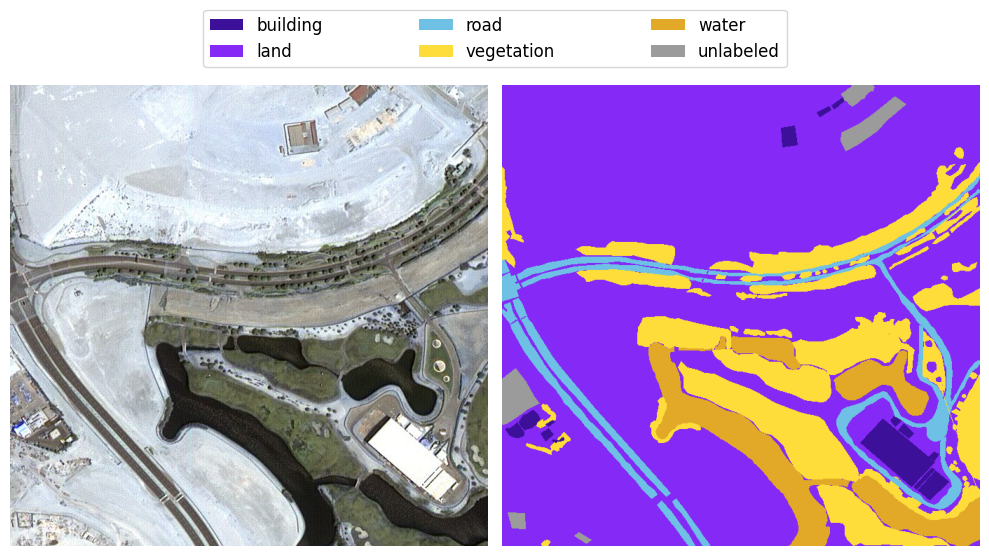

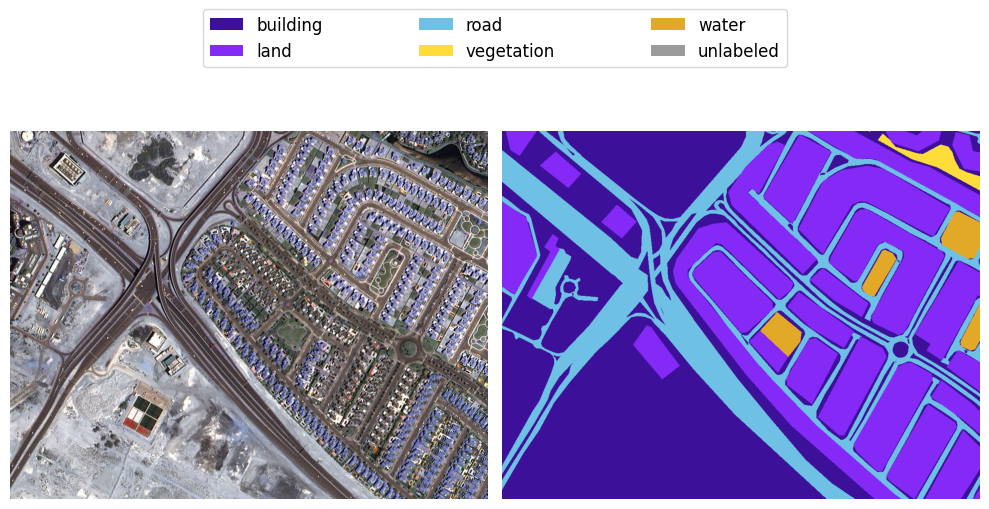

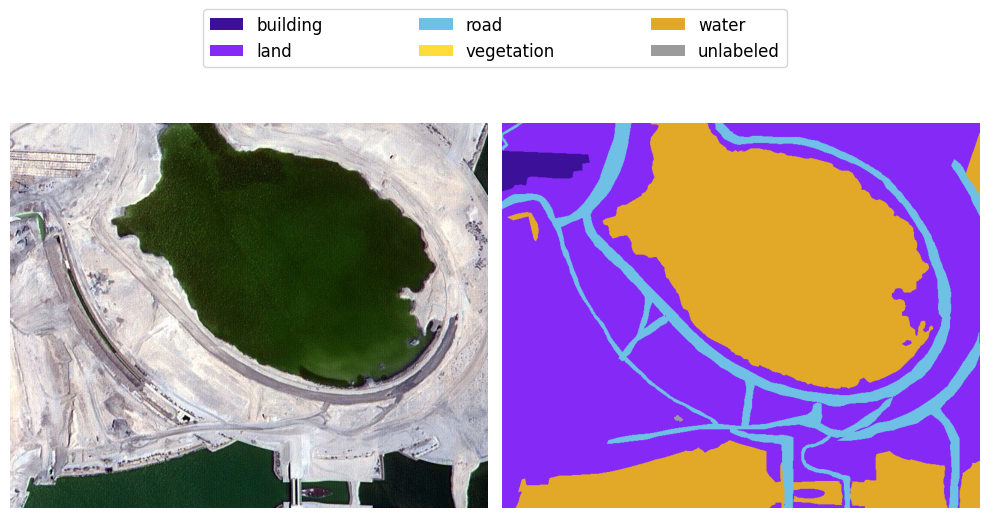

In [4]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/kaggle_semantic_segmentation"
}
dataset = KaggleSemanticSegmentationDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(50);
dataset.show_image(60);

In [5]:
dataset.data_distribution_table()

,Number of pixels
building,12999178.0
land,50881460.0
road,10753289.0
vegetation,10852909.0
water,13044790.0
unlabeled,500617.0


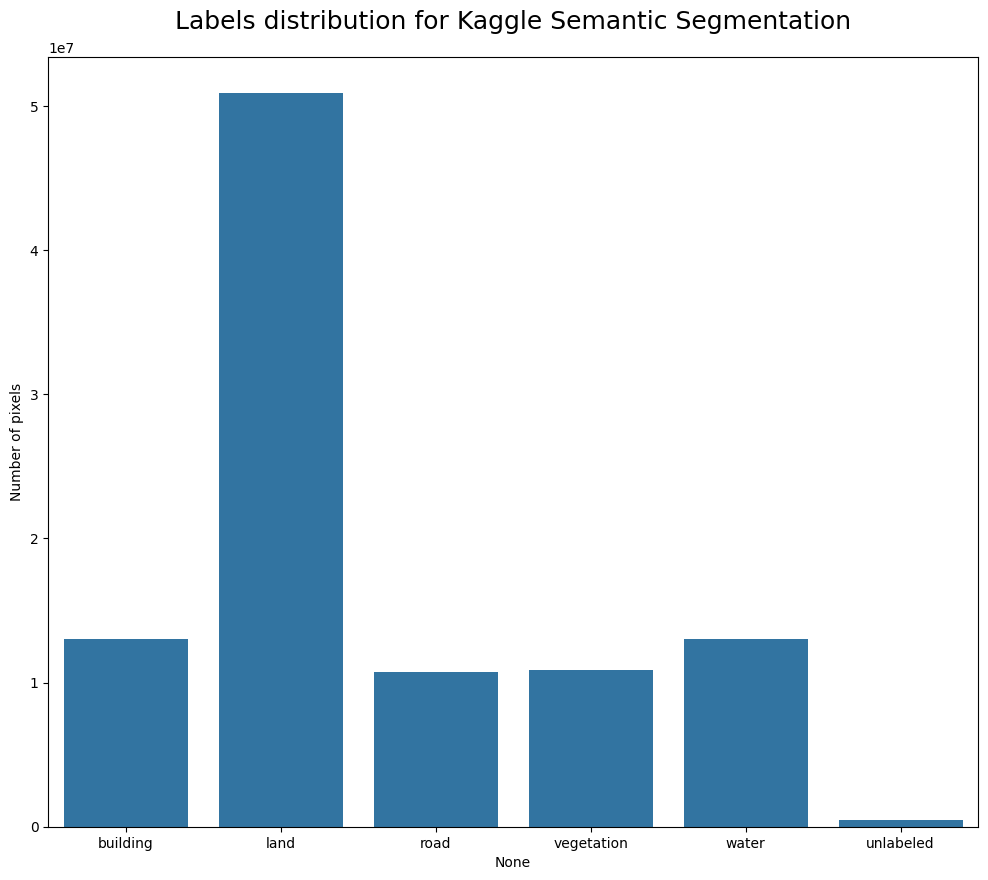

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [4]:
train_dataset_config = {
    "batch_size": 2,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/kaggle_semantic_segmentation",
    "csv_file": "/home/dragik/data/FAIR_EO/kaggle_semantic_segmentation/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = KaggleSemanticSegmentationDataset(train_dataset_config)
len(train_dataset)

58

## Create the model

In [5]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/kaggle_semantic_segmentation"
model_config = {
    "num_classes": 6, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [10]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-06 13:13:03,627 INFO Starting training.
training: 100%|██████████| 29/29 [05:02<00:00, 10.43s/it]
2025-03-06 13:18:06,157 INFO epoch: 1, time: 303, loss:  0.73454
testing on train set: 100%|██████████| 29/29 [03:48<00:00,  7.89s/it]
2025-03-06 13:21:56,451 INFO IOU:0.24005194393304144, IOU mean:0.1954928877106407, IOU per Class:[0.20364002 0.41509203 0.10907789 0.11518041 0.32031444 0.00965253]
training: 100%|██████████| 29/29 [04:32<00:00,  9.39s/it]
2025-03-06 13:26:28,657 INFO epoch: 2, time: 272, loss:  0.68346
testing on train set: 100%|██████████| 29/29 [03:36<00:00,  7.46s/it]
2025-03-06 13:30:05,035 INFO IOU:0.3163218575207689, IOU mean:0.2510082318628298, IOU per Class:[0.20240006 0.45573255 0.13946329 0.15393682 0.54002828 0.01448839]
training: 100%|██████████| 29/29 [03:44<00:00,  7.72s/it]
2025-03-06 13:33:49,051 INFO epoch: 3, time: 224, loss:  0.64930
testing on train set: 100%|██████████| 29/29 [03:57<00:00,  8.19s/it]
2025-03-06 13:37:46,631 INFO IOU:0.318864690

## Evaluate the model

In [11]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/kaggle_semantic_segmentation",
    "csv_file": "/home/dragik/data/FAIR_EO/kaggle_semantic_segmentation/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = KaggleSemanticSegmentationDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/kaggle_semantic_segmentation/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

7


2025-03-06 14:38:15,267 INFO Loading checkpoint /home/dragik/data/FAIR_EO/kaggle_semantic_segmentation/checkpoint.pth.tar
2025-03-06 14:38:15,651 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/kaggle_semantic_segmentation/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 2/2 [00:46<00:00, 23.07s/it]


[{'IOU': 0.36594436387343166,
  'IOU mean': 0.28207163661524476,
  'IOU per Class': array([0.20154638, 0.42163561, 0.14448621, 0.15949359, 0.76526802,
         0.        ])}]

## Predictions

2025-03-10 09:41:16,191 INFO Loading checkpoint /home/dragik/data/FAIR_EO/kaggle_semantic_segmentation/checkpoint.pth.tar
2025-03-10 09:41:16,725 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/kaggle_semantic_segmentation/checkpoint.pth.tar at epoch 11


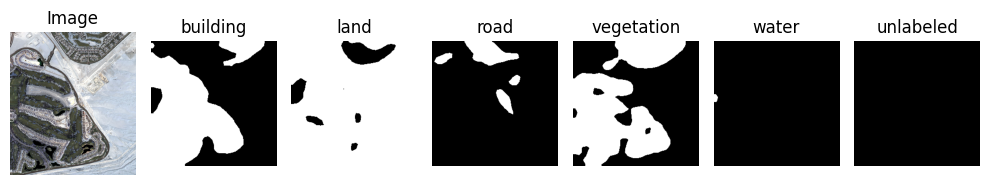

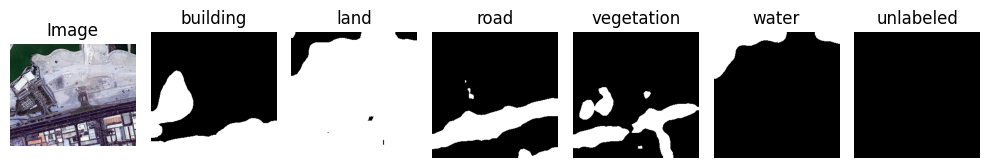

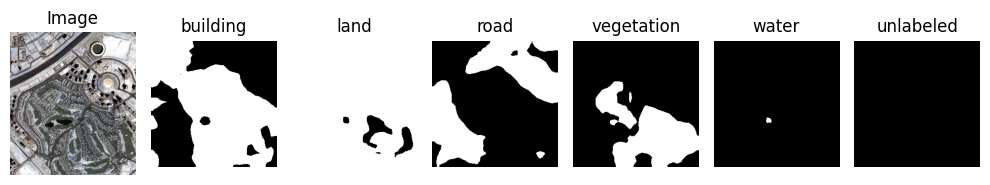

In [6]:
model_path = "/home/dragik/data/FAIR_EO/kaggle_semantic_segmentation/checkpoint.pth.tar"
labels = ["building","land","road","vegetation","water","unlabeled"]
transform = ResizeToTensor()
model.load_model(model_path)
csv_file = "/home/dragik/data/FAIR_EO/kaggle_semantic_segmentation/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('/home/dragik/data/FAIR_EO/kaggle_semantic_segmentation/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/kaggle_semantic_segmentation/' + test_list[1])
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/kaggle_semantic_segmentation/' + test_list[5])
fig = model.predict_masks(image, labels, transform)